# 01. Knowledge Base và Knowledge Graph
Chương 4.2 và 4.4–4.5. Đọc dataset gốc; thống kê chất lượng; xây và lưu KG thực tế; truy vấn và vẽ đồ thị.

UCI: 101.766 lượt nhập viện. Đồ thị bệnh án dùng mẫu ngẫu nhiên cố định 5.000 lượt để minh họa, không coi mã chẩn đoán hay quan hệ dữ liệu là khuyến nghị điều trị. KG tài liệu dùng toàn bộ corpus NIDDK và FinQA dev. Không đưa trường đáp án FinQA vào KG/corpus.

In [1]:
from pathlib import Path
import sys, json, time, random, platform, importlib.metadata as metadata
ROOT = Path.cwd().resolve()
while not (ROOT / 'data/chapter04').exists():
    if ROOT.parent == ROOT: raise RuntimeError('Không tìm thấy thư mục dự án')
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
DATA = ROOT / 'data/chapter04'
RESULT = ROOT / 'results/chapter04'
FIG = ROOT / 'docs/report_chapter_04'
RESULT.mkdir(parents=True, exist_ok=True)
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
random.seed(42); np.random.seed(42)
plt.rcParams.update({'figure.dpi': 110, 'font.size': 11})
environment = {'python': platform.python_version(), 'platform': platform.platform(),
    'packages': {p: metadata.version(p) for p in ['numpy','pandas','networkx','torch','transformers','nbclient','fastapi']}}
display(pd.DataFrame(environment['packages'].items(), columns=['Thư viện','Phiên bản']))

,Thư viện,Phiên bản
0,numpy,2.5.2
1,pandas,3.0.5
2,networkx,3.6.1
3,torch,2.13.0
4,transformers,4.57.6
5,nbclient,0.11.0
6,fastapi,0.141.1


## 1. Đọc và kiểm tra toàn bộ dataset

In [2]:
diabetes = pd.read_csv(DATA / 'diabetic_data.csv', dtype={'diag_1':str,'diag_2':str,'diag_3':str})
finqa = {s: json.loads((DATA / f'finqa_{s}.json').read_text(encoding='utf-8')) for s in ['train','dev','test']}
diabetes_chunks = [json.loads(x) for x in (DATA / 'diabetes_corpus.jsonl').read_text(encoding='utf-8').splitlines()]
profile = pd.DataFrame([
    ['UCI',len(diabetes),len(diabetes.columns),diabetes.patient_nbr.nunique()],
    ['FinQA train',len(finqa['train']),None,None], ['FinQA dev',len(finqa['dev']),None,None],
    ['FinQA test',len(finqa['test']),None,None], ['NIDDK chunks',len(diabetes_chunks),None,None]],
    columns=['Dataset','Số dòng/mẫu','Số cột','Bệnh nhân khác nhau'])
display(profile); display(diabetes.head(5))
assert len(diabetes) == 101766 and len(finqa['dev']) == 883

,Dataset,Số dòng/mẫu,Số cột,Bệnh nhân khác nhau
0,UCI,101766,50.0,71518.0
1,FinQA train,6251,NaN,NaN
2,FinQA dev,883,NaN,NaN
3,FinQA test,1147,NaN,NaN
4,NIDDK chunks,183,NaN,NaN


,encounter_id,patient_nbr,race,gender,age,weight,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,...,citoglipton,insulin,glyburide-metformin,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed,readmitted
0,2278392,8222157,Caucasian,Female,[0-10),?,6,25,1,1,...,No,No,No,No,No,No,No,No,No,NO
1,149190,55629189,Caucasian,Female,[10-20),?,1,1,7,3,...,No,Up,No,No,No,No,No,Ch,Yes,>30
2,64410,86047875,AfricanAmerican,Female,[20-30),?,1,1,7,2,...,No,No,No,No,No,No,No,No,Yes,NO
3,500364,82442376,Caucasian,Male,[30-40),?,1,1,7,2,...,No,Up,No,No,No,No,No,Ch,Yes,NO
4,16680,42519267,Caucasian,Male,[40-50),?,1,1,7,1,...,No,Steady,No,No,No,No,No,Ch,Yes,NO


## 2. Phân tích nhãn và dữ liệu thiếu

,Số lượt
readmitted,
NO,54864
>30,35545
<30,11357


,Thiếu,Tỷ lệ %
weight,98569,96.858479
max_glu_serum,96420,94.746772
A1Cresult,84748,83.277322
medical_specialty,49949,49.082208
payer_code,40256,39.557416
race,2273,2.233555
diag_3,1423,1.398306
diag_2,358,0.351787


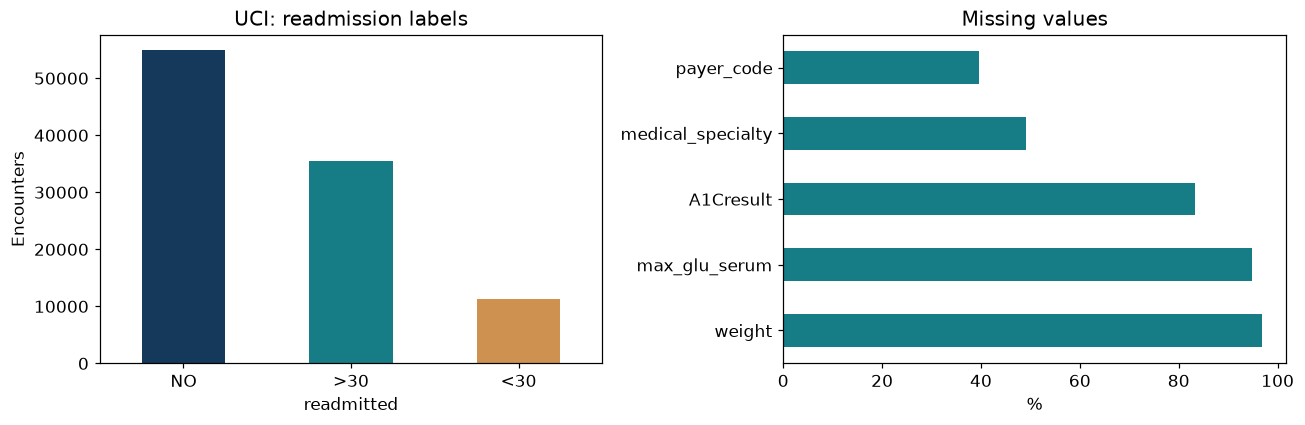

In [3]:
label_counts = diabetes.readmitted.value_counts().reindex(['NO','>30','<30'])
missing = (diabetes.eq('?') | diabetes.isna()).sum().sort_values(ascending=False)
missing_table = pd.DataFrame({'Thiếu':missing,'Tỷ lệ %':missing/len(diabetes)*100})
display(label_counts.rename('Số lượt').to_frame()); display(missing_table.head(8))
fig, axes = plt.subplots(1,2,figsize=(12,4))
label_counts.plot.bar(ax=axes[0],color=['#15395B','#167C86','#CE9150'])
axes[0].set(title='UCI: readmission labels',ylabel='Encounters'); axes[0].tick_params(axis='x',rotation=0)
missing_table['Tỷ lệ %'].head(5).plot.barh(ax=axes[1],color='#167C86')
axes[1].set(title='Missing values',xlabel='%'); fig.tight_layout()
fig.savefig(FIG/'uci_profile.png',bbox_inches='tight'); plt.show()

## 3. Xây KG bệnh án mẫu và hai KG tài liệu

In [4]:
from src.chapter04.retrieval import build_finance_chunks
from src.chapter04.knowledge import build_document_graph, build_encounter_graph, save_graph, load_graph
sample = diabetes.sample(n=5000,random_state=42).copy()
encounter_graph = build_encounter_graph(sample)
diabetes_graph = build_document_graph(diabetes_chunks,'diabetes')
finance_chunks = build_finance_chunks(finqa['dev'],table_headers=True)
finance_graph = build_document_graph(finance_chunks,'finance')
(DATA/'finance_corpus.jsonl').write_text(chr(10).join(json.dumps(x,ensure_ascii=False) for x in finance_chunks)+chr(10),encoding='utf-8')
graphs = {'encounters_sample5000':encounter_graph,'diabetes_documents':diabetes_graph,'finance':finance_graph}
graph_stats = []
for name,graph in graphs.items():
    path = ROOT/'knowledge_graph/chapter04'/f'{name}_graph.json.gz'
    save_graph(graph,path)
    restored = load_graph(path)
    assert restored.number_of_nodes() == graph.number_of_nodes()
    assert restored.number_of_edges() == graph.number_of_edges()
    graph_stats.append({'graph':name,'nodes':graph.number_of_nodes(),'edges':graph.number_of_edges(),
                        'node_types':dict(pd.Series([a['type'] for _,a in graph.nodes(data=True)]).value_counts())})
display(pd.DataFrame(graph_stats).drop(columns='node_types'))

,graph,nodes,edges
0,encounters_sample5000,10405,24650
1,diabetes_documents,187,183
2,finance,9573,9476


## 4. Truy vấn quan hệ và kiểm tra số liệu với CSV

In [5]:
patients = [n for n,a in encounter_graph.nodes(data=True) if a['type']=='Patient']
patient = max(patients,key=encounter_graph.out_degree)
encounters = list(encounter_graph.successors(patient))
display(pd.DataFrame([encounter_graph.nodes[n] for n in encounters]))
graph_count = sum(a.get('readmitted')=='<30' for _,a in encounter_graph.nodes(data=True))
csv_count = int((sample.readmitted=='<30').sum())
assert graph_count == csv_count
companies = [n for n,a in finance_graph.nodes(data=True) if a['type']=='Company']
company = max(companies,key=finance_graph.out_degree)
reports = list(finance_graph.successors(company))
display(pd.DataFrame([finance_graph.nodes[n] for n in reports]).head(6))
print('Graph/CSV <30:',graph_count,'; Company:',company,'; Indexed report contexts:',len(reports))

,type,encounter_id,age,readmitted,time_in_hospital
0,Encounter,236684916,[70-80),>30,2
1,Encounter,167289576,[70-80),>30,2
2,Encounter,266684442,[80-90),>30,3
3,Encounter,195657792,[70-80),<30,3


,type,year,filename,source_url
0,Report,2011,ETR/2011/page_341.pdf,https://github.com/czyssrs/FinQA
1,Report,2004,ETR/2004/page_213.pdf,https://github.com/czyssrs/FinQA
2,Report,2015,ETR/2015/page_131.pdf,https://github.com/czyssrs/FinQA
3,Report,2017,ETR/2017/page_114.pdf,https://github.com/czyssrs/FinQA
4,Report,2003,ETR/2003/page_84.pdf,https://github.com/czyssrs/FinQA
5,Report,2002,ETR/2002/page_86.pdf,https://github.com/czyssrs/FinQA


Graph/CSV <30: 570 ; Company: company:ETR ; Indexed report contexts: 18


## 5. Vẽ đồ thị và lưu kết quả

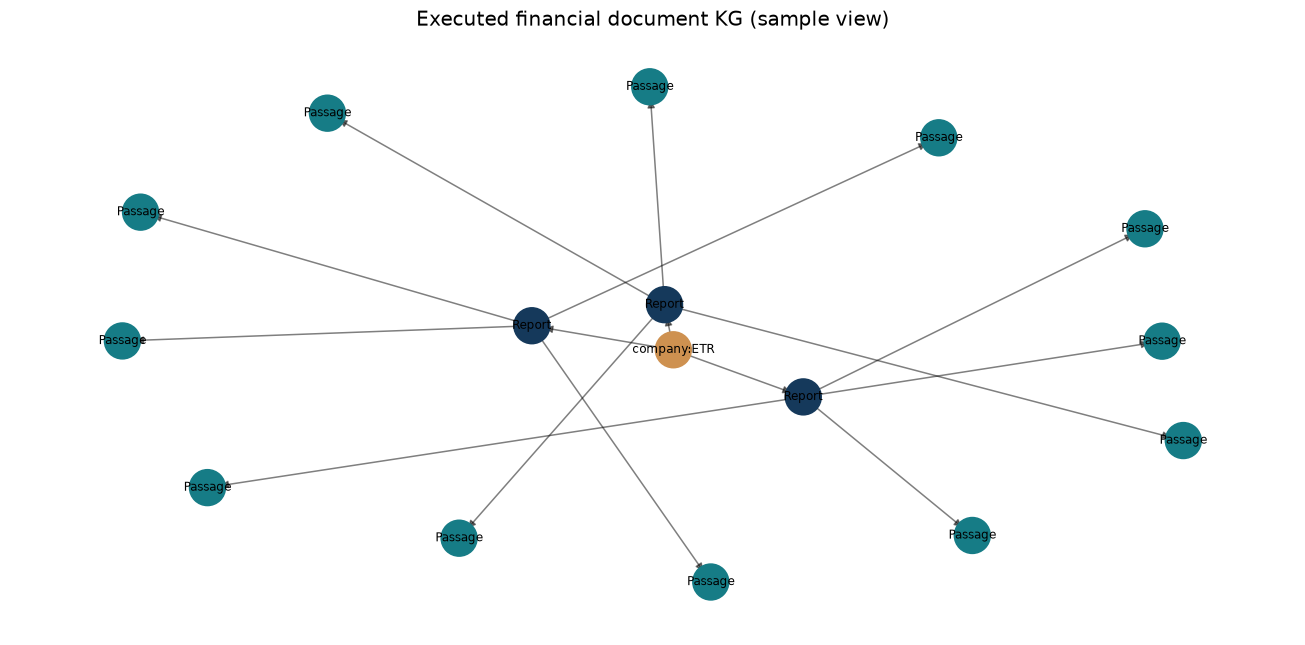

Saved graph artifacts and kb_results.json


In [6]:
import networkx as nx
focus = [company]+reports[:3]
for r in reports[:3]: focus += list(finance_graph.successors(r))[:4]
sub = finance_graph.subgraph(focus)
pos = nx.spring_layout(sub,seed=42)
fig,ax=plt.subplots(figsize=(12,6))
colors = {'Company':'#CE9150','Report':'#15395B','Passage':'#167C86','TableRow':'#75B8C0'}
nx.draw_networkx_nodes(sub,pos,node_color=[colors[sub.nodes[n]['type']] for n in sub],node_size=550,ax=ax)
nx.draw_networkx_edges(sub,pos,arrows=True,alpha=.5,ax=ax)
labels = {n:(n if n.startswith('company:') else 'Report' if n.startswith('report:') else sub.nodes[n]['type']) for n in sub}
nx.draw_networkx_labels(sub,pos,labels,font_size=8,ax=ax)
ax.set_title('Executed financial document KG (sample view)'); ax.axis('off'); fig.tight_layout()
fig.savefig(FIG/'executed_finance_graph.png',bbox_inches='tight');plt.show()
kb_result = {'profile':profile.fillna('').to_dict('records'),'graphs':graph_stats,
    'encounter_sample_size':5000,'seed':42,'sample_readmitted_under30':graph_count,
    'full_dataset_rows':len(diabetes),'finance_chunks':len(finance_chunks),'environment':environment}
(RESULT/'kb_results.json').write_text(json.dumps(kb_result,ensure_ascii=False,indent=2,default=int),encoding='utf-8')
print('Saved graph artifacts and kb_results.json')

## Nhận xét
KG tài chính ở đây là đồ thị công ty → context báo cáo → đoạn/dòng bảng, giữ locator và nguồn. Chưa trích ontology kế toán đầy đủ hoặc thêm quan hệ nhân quả. Mẫu UCI chọn từ toàn dataset bằng seed 42; không báo cáo chỉ số của mẫu như thể đó là toàn bộ 101.766 lượt. Các query đã đối chiếu với CSV và graph round-trip đã được kiểm tra.